In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../CSVs/asbesto_cancer.csv')

In [3]:
# Variable de entrada 
x_train = df.iloc[0:10,0].values
# Variable objetivo
y_train = df.iloc[0:10,1].values

print(f'x_train: {x_train}')
print(f'y_train: {y_train}')

x_train: [  50  400  500  900 1100 1600 1800 2000 3000]
y_train: [ 2  6  5 10 26 42 37 28 50]


In [4]:
m = x_train.shape[0]
print(f'm: {m}')

m: 9


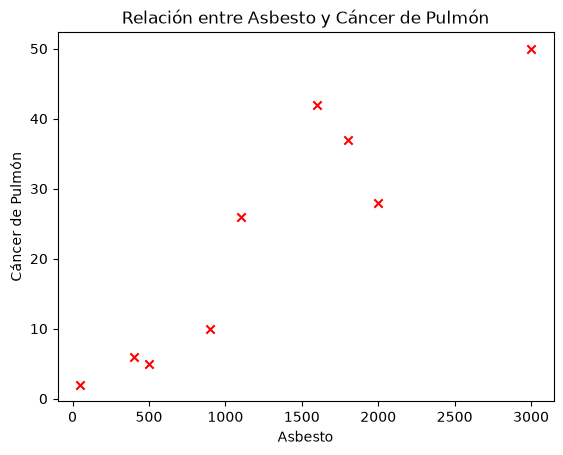

In [5]:
plt.scatter(x_train, y_train, color='red', marker='x')
plt.title('Relación entre Asbesto y Cáncer de Pulmón')
plt.xlabel('Asbesto')
plt.ylabel('Cáncer de Pulmón')
plt.show()

In [6]:
def compute_cost(x, y, w, b):
    """
    Calcula la función de costo (error cuadrático medio) de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos de entrada, m ejemplos.
        y (ndarray (m,)): Valores objetivo.
        w,b (scalar): Parámetros del modelo.
    Returns:
        costo (float): J(w,b) = (1/2m) * Σ (f_wb(x_i) - y_i)^2
    """
    m = x.shape[0]
    f_wb = w * x + b
    return np.sum((f_wb - y) ** 2) / (2 * m)

w = 0.025, b = -5 -> costo = 47.55
w = 0.01, b = +10 -> costo = 43.51
w = 0.015, b = +5 -> costo = 23.93
w = 0.018, b = +0 -> costo = 20.61


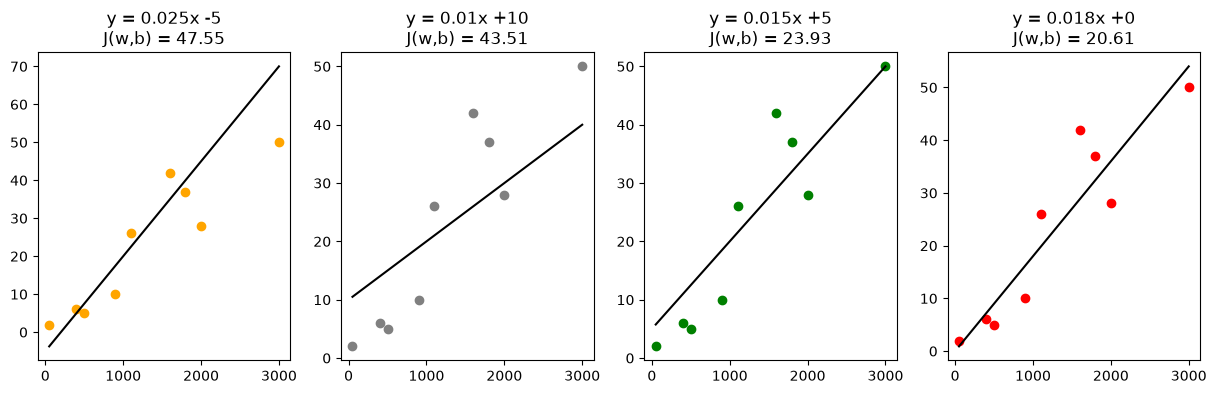

In [7]:
# Ecuaciones candidatas (w, b), de mayor a menor costo
candidatos = [(0.025, -5), (0.01, 10), (0.015, 5), (0.018, 0)]
colores = ['orange', 'gray', 'green', 'red']

fig, axs = plt.subplots(1,4, figsize=(15,4))

for ax, (w_c, b_c), color in zip(axs, candidatos, colores):
    y_p = w_c * x_train + b_c
    costo = compute_cost(x_train, y_train, w_c, b_c)
    ax.scatter(x_train, y_train, color=color)
    ax.plot(x_train, y_p, color='black')
    ax.set_title(f'y = {w_c}x {b_c:+}\nJ(w,b) = {costo:.2f}')
    print(f'w = {w_c}, b = {b_c:+} -> costo = {costo:.2f}')

plt.show()

In [8]:
def compute_model_output(x, w, b):
    """
    Calcula la predicción de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos, m ejemplos.
        w,b (scalar): Parámetros del modelo.
    Returns:
        f_wb (ndarray (m,)): Predicciones del modelo.
    """
    m = x.shape[0]
    f_wb = np.zeros(m)

    for i in range(m):
        f_wb[i] = w * x[i] + b

    return f_wb

In [9]:
# Valores óptimos (menor costo entre los candidatos)
w = 0.018
b = 0
f_wb = compute_model_output(x_train, w, b)
print(f'Costo con w={w}, b={b}: {compute_cost(x_train, y_train, w, b):.2f}')

Costo con w=0.018, b=0: 20.61


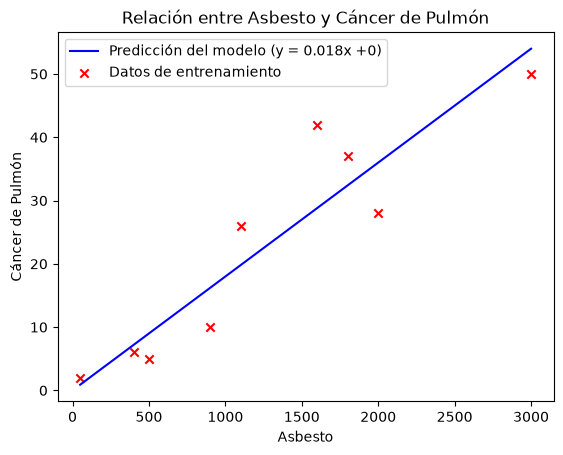

In [10]:
plt.plot(x_train, f_wb, color='blue', label=f'Predicción del modelo (y = {w}x {b:+})')
plt.scatter(x_train, y_train, color='red', marker='x', label='Datos de entrenamiento')
plt.title('Relación entre Asbesto y Cáncer de Pulmón')
plt.xlabel('Asbesto')
plt.ylabel('Cáncer de Pulmón')
plt.legend()
plt.show()

In [11]:
x_i_1 = 800
porcentaje_cancer_1 = w * x_i_1 + b
print(f'Para un valor de Asbesto de {x_i_1}, el porcentaje de Cáncer de Pulmón predicho por el modelo es: {porcentaje_cancer_1:.4f}')

Para un valor de Asbesto de 800, el porcentaje de Cáncer de Pulmón predicho por el modelo es: 14.4000


In [12]:
x_i_2 = 1500
porcentaje_cancer_2 = w * x_i_2 + b
print(f'Para un valor de Asbesto de {x_i_2}, el porcentaje de Cáncer de Pulmón predicho por el modelo es: {porcentaje_cancer_2:.4f}')

Para un valor de Asbesto de 1500, el porcentaje de Cáncer de Pulmón predicho por el modelo es: 27.0000


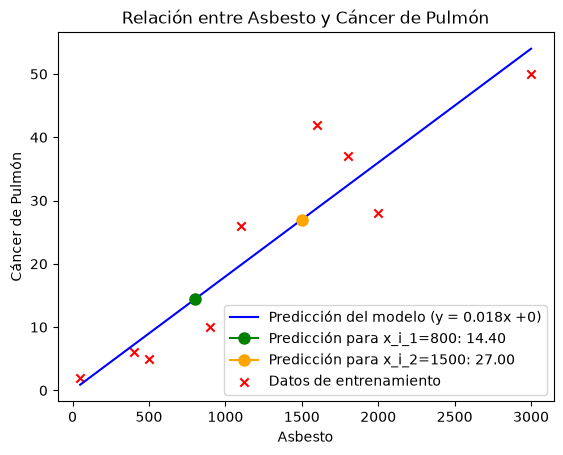

In [13]:
plt.plot(x_train, f_wb, color='blue', label=f'Predicción del modelo (y = {w}x {b:+})')
plt.plot(x_i_1, porcentaje_cancer_1, color='green', marker='o', markersize=8, label=f'Predicción para x_i_1={x_i_1}: {porcentaje_cancer_1:.2f}')
plt.plot(x_i_2, porcentaje_cancer_2, color='orange', marker='o', markersize=8, label=f'Predicción para x_i_2={x_i_2}: {porcentaje_cancer_2:.2f}')
plt.scatter(x_train, y_train, color='red', marker='x', label='Datos de entrenamiento')
plt.title('Relación entre Asbesto y Cáncer de Pulmón')
plt.xlabel('Asbesto')
plt.ylabel('Cáncer de Pulmón')
plt.legend()
plt.show()